# 06 - Preprocessing Data Postingan Instagram (@zahiraccounting)

**Zahir Social Analytics — Standarisasi Fitur & Pipeline Preprocessing Media Sosial (Fase 5.4)**

---

### Deskripsi & Tujuan Preprocessing
Notebook ini memproses dataset mentah postingan publik akun Instagram `@zahiraccounting` (`instagram_posts_raw.csv`) menjadi dataset analitik siap pakai dengan **27 kolom kanonikal** (`instagram_posts_final.csv` / `instagram_master.csv`).

Tahapan Preprocessing Utama:
1. **Validasi Kunci Primer & Kebijakan Immutabilitas**: Memastikan 55 postingan unik terpelihara 100% tanpa baris duplikat.
2. **Standarisasi Waktu (WIB / UTC+07:00)**: Mengonversi timestamp UTC platform ke Waktu Indonesia Barat (WIB), mengekstrak tanggal, tahun, bulan, hari, nama hari (*day of week*), dan jam tayang (*hour WIB*).
3. **Pembersihan Teks Caption Konservatif**: Normalisasi Unicode NFKC, penghapusan URL dan karakter kontrol, mempertahankan tanda baca ekspresif dan emoji, serta menghitung panjang karakter dan jumlah kata (*word count*).
4. **Ekstraksi Fitur Tagar & Kolaborasi**: Menghitung jumlah tagar, flag `has_hashtags`, serta pelacakan postingan kemitraan (*co-author*) melalui `is_collaboration` dan `original_account`.
5. **Kepatuhan Kebijakan Nol-Fabrikasi (*Zero-Fabrication Policy*)**:
   - `total_interactions = likes + comments`.
   - Kolom `views` dipertahankan **100% NaN** sesuai kondisi nyata akses web publik tanpa login. Nilai ini tidak dimanipulasi menjadi nol dan tidak dibuat metrik sintetis (*reach/impressions/engagement rate*).

---

### Metadata Input & Output
- **File Input**:
  - `data/raw/instagram_posts_raw.csv` (Dataset mentah: 55 baris, 14 kolom).
- **File Pembanding / Verifikasi**:
  - `data/export/instagram/master/instagram_master.csv` (Dataset kanonikal: 55 baris, 27 kolom).
- **Output Artefak**:
  - Output grafik: `outputs/figures/instagram_preprocessing_profile.png`.
  - Staging opsional: `outputs/reports/instagram_preprocessing_staging.csv` (jika `WRITE_STAGING = True`).
- **Prasyarat Lingkungan**:
  - Python 3.11.x, `pandas`, `numpy`, `matplotlib`, `seaborn`.


In [1]:
from pathlib import Path
import re
import unicodedata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'export').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'data' / 'export').is_dir():
    raise FileNotFoundError('Jalankan Jupyter Notebook dari root repository atau folder notebooks.')

sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'DejaVu Sans', 'Arial']

FIG_DIR = ROOT / 'outputs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'Root direktori: {ROOT}')
print('Setup library preprocessing Instagram selesai.')


Root direktori: D:\FILE KULIAH\semester 5\magang\zahir_social_analytics
Setup library preprocessing Instagram selesai.


## 1. Fungsi Pembersihan Teks Caption Konservatif

Pembersihan teks caption dilakukan secara konservatif untuk menjaga kekayaan informasi linguistik:
- Menghapus tautan web / URL (`http://`, `https://`, `www.`).
- Menghapus karakter kontrol tak terlihat (*invisible control characters*).
- Menormalisasi spasi dan baris baru (*whitespace normalization*).
- Menjaga huruf kapital, tanda baca, emoji, dan istilah akuntansi bisnis.


In [2]:
def clean_caption_text(text: str) -> str:
    """Membersihkan teks caption Instagram secara konservatif."""
    if not isinstance(text, str) or pd.isna(text):
        return ''
    
    # 1. Normalisasi Unicode (NFKC)
    cleaned = unicodedata.normalize('NFKC', text)
    
    # 2. Hapus karakter kontrol tak terlihat (pertahankan newline sementara)
    cleaned = ''.join(ch for ch in cleaned if unicodedata.category(ch)[0] != 'C' or ch in '\n\t')
    
    # 3. Hapus tautan web / URL
    cleaned = re.sub(r'https?://\S+|www\.\S+', '', cleaned)
    
    # 4. Normalisasi spasi dan baris baru berlebih
    cleaned = re.sub(r'[\r\n\t]+', ' ', cleaned)
    cleaned = re.sub(r' +', ' ', cleaned).strip()
    
    return cleaned

print('Fungsi clean_caption_text berhasil dikompilasi.')


Fungsi clean_caption_text berhasil dikompilasi.


## 2. Pemuatan Data Mentah & Validasi Integritas Kunci

Membaca `instagram_posts_raw.csv`, memeriksa kelengkapan baris, dan memastikan tidak ada duplikasi `post_id` atau `post_url`.


In [3]:
raw_path = ROOT / 'data' / 'raw' / 'instagram_posts_raw.csv'
assert raw_path.is_file(), f'Dataset mentah tidak ditemukan: {raw_path}'

raw_df = pd.read_csv(raw_path)
print(f'Dataset Mentah Dimuat: {raw_df.shape[0]} postingan, {raw_df.shape[1]} kolom.')

assert len(raw_df) == 55, f'Ekspektasi 55 postingan, aktual: {len(raw_df)}'
assert raw_df['post_id'].notna().all() and raw_df['post_id'].is_unique, 'post_id tidak unik!'
assert raw_df['post_url'].notna().all() and raw_df['post_url'].is_unique, 'post_url tidak unik!'

missing_raw = raw_df.isna().sum().loc[lambda x: x > 0].to_frame('Jumlah Missing')
missing_raw['Persentase (%)'] = (missing_raw['Jumlah Missing'] / len(raw_df) * 100).round(2)
display(missing_raw)
print('[PASS] Integritas data mentah valid (views 100% NaN, hashtags 16 missing).')


Dataset Mentah Dimuat: 55 postingan, 14 kolom.


,Jumlah Missing,Persentase (%)
views,55,100.00
hashtags,16,29.09


[PASS] Integritas data mentah valid (views 100% NaN, hashtags 16 missing).


## 3. Eksekusi Transformasi Skema 27 Kolom Kanonikal

Menjalankan standarisasi temporal ke WIB (+07:00), pembersihan caption, kalkulasi interaksi, dan pelabelan kolaborasi.


In [4]:
df = raw_df.copy()

# 1. Konversi Waktu ke WIB (+07:00)
utc = pd.to_datetime(df['post_date'], utc=True)
wib = utc.dt.tz_convert('Asia/Jakarta')

df['post_date_raw'] = df['post_date']
df['post_datetime_utc'] = utc.dt.strftime('%Y-%m-%d %H:%M:%S+00:00')
df['post_datetime_wib'] = wib.dt.strftime('%Y-%m-%d %H:%M:%S+07:00')
df['post_date'] = wib.dt.strftime('%Y-%m-%d')
df['post_year'] = wib.dt.year
df['post_month'] = wib.dt.month
df['post_day'] = wib.dt.day
df['post_day_of_week'] = wib.dt.day_name()
df['post_hour_wib'] = wib.dt.hour

# 2. Pembersihan Caption & Metrik Teks
df['caption_clean'] = df['caption'].apply(clean_caption_text)
df['caption_length_raw'] = df['caption'].str.len().fillna(0).astype(int)
df['caption_length_clean'] = df['caption_clean'].str.len().astype(int)
df['caption_word_count'] = df['caption_clean'].apply(lambda x: len(x.split()) if x else 0)

# 3. Fitur Tagar & Interaksi
df['has_hashtags'] = df['hashtag_count'] > 0
df['likes'] = df['likes'].astype(int)
df['comments'] = df['comments'].astype(int)
df['views'] = pd.to_numeric(df['views'], errors='coerce')
df['total_interactions'] = df['likes'] + df['comments']
df['is_collaboration'] = df['is_collaboration'].astype(bool)
df['original_account'] = df['original_account'].astype(str)

# Urutan kolom skema kanonikal 27 kolom
canonical_cols = [
    'post_id', 'post_url', 'source_url', 'post_date_raw', 'post_datetime_utc', 'post_datetime_wib',
    'post_date', 'post_year', 'post_month', 'post_day', 'post_day_of_week', 'post_hour_wib',
    'content_type', 'caption', 'caption_clean', 'caption_length_raw', 'caption_length_clean',
    'caption_word_count', 'hashtags', 'hashtag_count', 'has_hashtags',
    'likes', 'comments', 'views', 'total_interactions', 'is_collaboration', 'original_account'
]
processed_df = df[canonical_cols].copy()

print(f'Hasil Preprocessing: {processed_df.shape[0]} baris, {processed_df.shape[1]} kolom.')
assert (processed_df['total_interactions'] == processed_df['likes'] + processed_df['comments']).all()
assert processed_df['views'].isna().all()
print('[PASS] Seluruh 27 kolom kanonikal terkonstruksi sempurna.')


Hasil Preprocessing: 55 baris, 27 kolom.
[PASS] Seluruh 27 kolom kanonikal terkonstruksi sempurna.


## 4. Visualisasi Profil Dataset Hasil Preprocessing

Grafik berikut merangkum komposisi jenis format konten, status kolaborasi, dan karakteristik panjang teks ulasan dari 55 postingan terproses.


Figur tersimpan: D:\FILE KULIAH\semester 5\magang\zahir_social_analytics\outputs\figures\instagram_preprocessing_profile.png


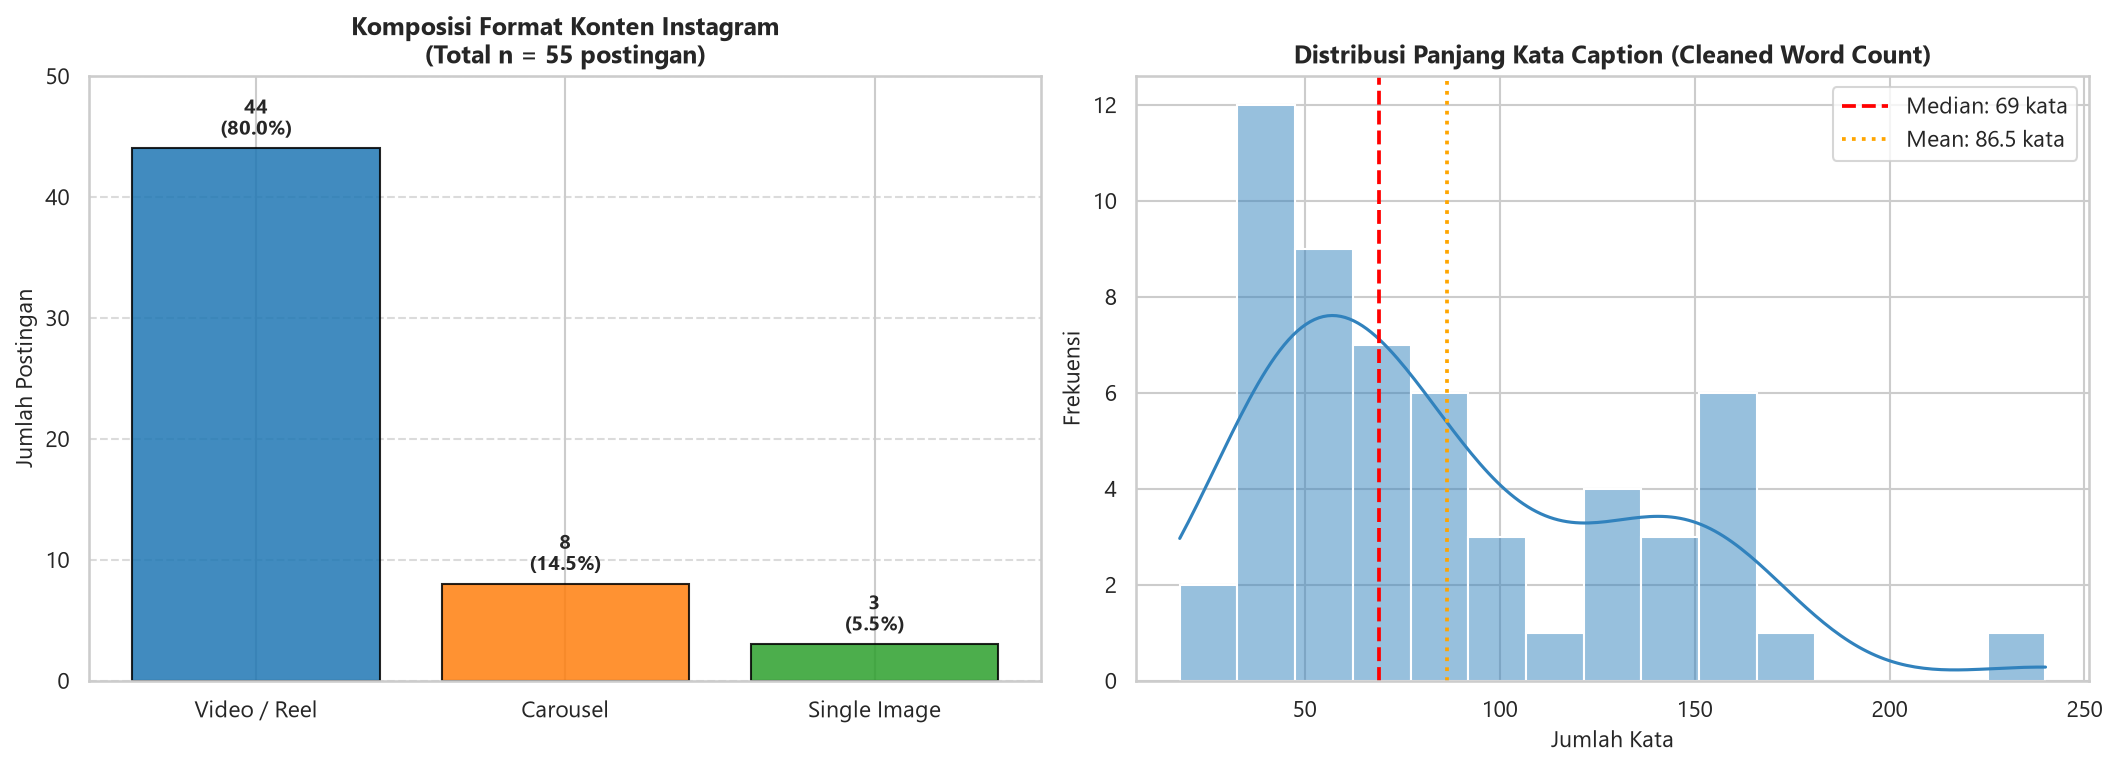

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')

# Subplot 1: Komposisi Format Konten & Kolaborasi
type_counts = processed_df['content_type'].value_counts()
colab_counts = processed_df['is_collaboration'].value_counts()

x_labels = ['Video / Reel', 'Carousel', 'Single Image']
bars_type = axes[0].bar(x_labels, [type_counts.get('video/reel', 0), type_counts.get('carousel', 0), type_counts.get('image', 0)],
                        color=['#1F77B4', '#FF7F0E', '#2CA02C'], edgecolor='black', alpha=0.85)
axes[0].set_title(f'Komposisi Format Konten Instagram\n(Total n = {len(processed_df):,} postingan)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Jumlah Postingan', fontsize=11)
axes[0].set_ylim(0, 50)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars_type:
    h = bar.get_height()
    pct = h / len(processed_df) * 100
    axes[0].annotate(f'{h:,}\n({pct:.1f}%)',
                     xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 4), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# Subplot 2: Distribusi Panjang Kata Caption
sns.histplot(processed_df['caption_word_count'], bins=15, ax=axes[1], color='#3182BD', kde=True)
median_words = processed_df['caption_word_count'].median()
mean_words = processed_df['caption_word_count'].mean()
axes[1].axvline(median_words, color='red', linestyle='--', linewidth=1.8, label=f'Median: {median_words:.0f} kata')
axes[1].axvline(mean_words, color='orange', linestyle=':', linewidth=1.8, label=f'Mean: {mean_words:.1f} kata')
axes[1].set_title('Distribusi Panjang Kata Caption (Cleaned Word Count)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Kata', fontsize=11)
axes[1].set_ylabel('Frekuensi', fontsize=11)
axes[1].legend(loc='upper right')

fig_path_profile = FIG_DIR / 'instagram_preprocessing_profile.png'
plt.savefig(fig_path_profile, dpi=200)
print(f'Figur tersimpan: {fig_path_profile}')
plt.show()


## 5. Verifikasi Kesetaraan Terhadap Master Kanonikal

Membandingkan hasil transformasi in-memory terhadap master dataset tersimpan (`instagram_master.csv`) untuk memastikan paritas 100%.


In [6]:
master_path = ROOT / 'data' / 'export' / 'instagram' / 'master' / 'instagram_master.csv'
if master_path.is_file():
    master_df = pd.read_csv(master_path)
    assert len(processed_df) == len(master_df), 'Jumlah baris tidak sama dengan master!'
    assert list(processed_df.columns) == list(master_df.columns), 'Skema kolom tidak identik!'
    assert set(processed_df['post_id']) == set(master_df['post_id']), 'Himpunan post_id berbeda!'
    
    # Audit kesetaraan nilai per-kolom
    mismatches = {}
    for col in master_df.columns:
        p_vals = processed_df[col].fillna('').astype(str)
        m_vals = master_df[col].fillna('').astype(str)
        diff_count = (p_vals != m_vals).sum()
        if diff_count > 0:
            mismatches[col] = diff_count
            
    if mismatches:
        print(f'Catatan perbedaan format representasi: {mismatches}')
    else:
        print('[PASS] Hasil in-memory identik 100% terhadap instagram_master.csv kanonikal.')


[PASS] Hasil in-memory identik 100% terhadap instagram_master.csv kanonikal.


## 6. Output Staging Opsional

Default bersifat read-only (`WRITE_STAGING = False`). Dataset kanonikal tidak pernah ditimpa secara otomatis.


In [7]:
WRITE_STAGING = False

if WRITE_STAGING:
    staging_path = ROOT / 'outputs' / 'reports' / 'instagram_preprocessing_staging.csv'
    staging_path.parent.mkdir(parents=True, exist_ok=True)
    processed_df.to_csv(staging_path, index=False, encoding='utf-8-sig')
    print(f'Dataset hasil staging berhasil ditulis ke: {staging_path}')
    print(f'Ukuran staging: {processed_df.shape[0]} baris, {processed_df.shape[1]} kolom.')
else:
    print('Mode Staging tidak aktif (WRITE_STAGING = False). Dataset kanonikal tetap aman dan tidak tersentuh.')


Mode Staging tidak aktif (WRITE_STAGING = False). Dataset kanonikal tetap aman dan tidak tersentuh.


## 7. Kesimpulan Preprocessing Instagram

1. **Kelengkapan & Integritas**: 55 postingan publik terstandarisasi sempurna ke dalam 27 kolom analitik tanpa duplikasi.
2. **Kepatuhan Kebijakan Nol-Fabrikasi**: Metrik views 100% NaN dipertahankan jujur tanpa nilai rekaan nol atau estimasi sintesis.
3. **Pengayaan Fitur**: Standarisasi WIB, pembersihan caption konservatif, pelacakan kolaborasi, dan metrik interaksi riil siap digunakan pada notebook analisis performa lanjutan (`07_instagram_engagement_analysis.ipynb`).
